# Entraînement et comparaison des modèles

In [4]:
import os
import joblib
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.pipeline import Pipeline
from sklearn.base import clone
from sklearn.metrics import (
    accuracy_score, 
    precision_score,
    recall_score,
    f1_score,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt
from sklearn.model_selection import GridSearchCV

In [5]:
chemin_data = os.path.join(
    "..",
    "data"
)

In [6]:
# chargement des données séparées
X_train = joblib.load(
    os.path.join(
        chemin_data,
        "X_train.joblib"
    )
)
X_test = joblib.load(
    os.path.join(
        chemin_data,
        "X_test.joblib"
    )
)

y_train = joblib.load(
    os.path.join(
        chemin_data,
        "y_train.joblib"
    )
)
y_test = joblib.load(
    os.path.join(
        chemin_data,
        "y_test.joblib"
    )
)

display(f"shape of X_train: {X_train.shape}")
display(f"shape of X_test: {X_test.shape}")
display(f"shape of y_train: {y_train.shape}")
display(f"shape of y_test: {y_test.shape}")

'shape of X_train: (1600, 13)'

'shape of X_test: (400, 13)'

'shape of y_train: (1600,)'

'shape of y_test: (400,)'

In [7]:
chemin_stockage = os.path.join("..", "src")

In [8]:
preprocessing = joblib.load(
    os.path.join(
        chemin_stockage,
        "preprocessing_pipeline.joblib"
    )
)
preprocessing

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('Imputation', ...), ('Encoding', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('mcar_num', ...), ('mcar_cat', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'passthrough'
,"verbose_feature_names_out verbo

In [9]:
# Entraînement du modèle Régression logistique
rl_pipeline = Pipeline(
    steps=[
        ("preprocessing", clone(preprocessing)),
        ("entrainement", LogisticRegression(class_weight="balanced"))
    ]
)

rl_pipeline.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessing', ...), ('entrainement', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[object](3,)","['High','Low','Medium']"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](13,)","['Year_of_Study','Sleep_Hours','Study_Hours_Per_Week',...,'Part_Time_Job', 'Diet_Quality','Previous_Mental_Health_History']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,13
,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('Imputation', ...), ('Encoding', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore f

In [10]:
# Entraînement du modèle SVC
svc_pipeline = Pipeline(
    steps=[
        ("preprocessing", clone(preprocessing)),
        ("entraînement", SVC(class_weight="balanced"))
    ]
)

svc_pipeline.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessing', ...), ('entraînement', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[object](3,)","['High','Low','Medium']"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](13,)","['Year_of_Study','Sleep_Hours','Study_Hours_Per_Week',...,'Part_Time_Job', 'Diet_Quality','Previous_Mental_Health_History']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,13
,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('Imputation', ...), ('Encoding', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore f

In [11]:
# Entraînement du modèle Descision Tree
dt_pipeline = Pipeline(
    steps=[
        ("preprocessing", clone(preprocessing)),
        ("entraînement", DecisionTreeClassifier())
    ]
)

dt_pipeline.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessing', ...), ('entraînement', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[object](3,)","['High','Low','Medium']"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](13,)","['Year_of_Study','Sleep_Hours','Study_Hours_Per_Week',...,'Part_Time_Job', 'Diet_Quality','Previous_Mental_Health_History']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,13
,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('Imputation', ...), ('Encoding', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore f

In [12]:
# Utilisation de mêmes données de test pour comparer les modèles
y_preds = {
    "LogisticRegression": rl_pipeline.predict(X_test),
    "SVC": svc_pipeline.predict(X_test),
    "DecisionTree": dt_pipeline.predict(X_test)
}

for key, value in y_preds.items():
    print(f"Prédictions du modèle :{key}")
    display(value)

Prédictions du modèle :LogisticRegression


array(['Medium', 'High', 'Low', 'High', 'Medium', 'Medium', 'High',
       'High', 'Low', 'Medium', 'High', 'Low', 'High', 'Medium', 'High',
       'Medium', 'High', 'High', 'Medium', 'Low', 'Low', 'High', 'Medium',
       'Low', 'Medium', 'Medium', 'Medium', 'High', 'Low', 'Low', 'Low',
       'Low', 'Low', 'High', 'Medium', 'High', 'Low', 'Low', 'High',
       'Medium', 'Low', 'Medium', 'High', 'Low', 'Medium', 'Medium',
       'High', 'Low', 'Low', 'High', 'High', 'High', 'Low', 'Low',
       'Medium', 'High', 'Medium', 'Medium', 'High', 'High', 'Low',
       'High', 'Low', 'High', 'Medium', 'Medium', 'High', 'High', 'Low',
       'High', 'High', 'Low', 'Medium', 'High', 'Low', 'Low', 'Medium',
       'High', 'Low', 'Low', 'Medium', 'High', 'High', 'High', 'Medium',
       'High', 'High', 'Low', 'Medium', 'High', 'Medium', 'Medium',
       'Medium', 'Low', 'Medium', 'Low', 'Medium', 'Medium', 'High',
       'Medium', 'High', 'High', 'Medium', 'Medium', 'High', 'High',
       'Medium

Prédictions du modèle :SVC


array(['Medium', 'High', 'Low', 'High', 'Medium', 'Medium', 'High',
       'Medium', 'Low', 'Medium', 'High', 'Low', 'High', 'Medium', 'High',
       'Medium', 'Medium', 'High', 'Medium', 'Low', 'Low', 'High',
       'Medium', 'Low', 'High', 'High', 'Medium', 'Medium', 'Low',
       'Medium', 'Low', 'Low', 'Low', 'High', 'Low', 'High', 'Low', 'Low',
       'High', 'Medium', 'Low', 'Medium', 'High', 'Low', 'Medium',
       'Medium', 'Medium', 'Low', 'Low', 'High', 'High', 'High', 'Low',
       'Low', 'Medium', 'High', 'Medium', 'Medium', 'High', 'High', 'Low',
       'High', 'Low', 'High', 'Medium', 'Medium', 'High', 'High',
       'Medium', 'High', 'Medium', 'Low', 'Medium', 'High', 'Low', 'Low',
       'Medium', 'Medium', 'Low', 'Medium', 'Medium', 'High', 'High',
       'High', 'Medium', 'High', 'High', 'Low', 'Medium', 'High', 'High',
       'Medium', 'Medium', 'Low', 'Medium', 'Low', 'Medium', 'Medium',
       'High', 'High', 'High', 'High', 'Low', 'Medium', 'High', 'High',
       

Prédictions du modèle :DecisionTree


array(['High', 'High', 'Low', 'High', 'High', 'High', 'High', 'Medium',
       'Low', 'Medium', 'High', 'Medium', 'High', 'High', 'Medium',
       'High', 'High', 'High', 'Low', 'Low', 'Medium', 'High', 'Low',
       'Low', 'High', 'Medium', 'Medium', 'Low', 'Low', 'Medium', 'Low',
       'Low', 'High', 'High', 'Low', 'High', 'Medium', 'Medium', 'High',
       'Medium', 'Low', 'Medium', 'High', 'Low', 'High', 'Low', 'High',
       'Medium', 'Low', 'Medium', 'Medium', 'High', 'Low', 'Medium',
       'Low', 'Medium', 'Medium', 'Low', 'High', 'Low', 'Low', 'High',
       'Low', 'Medium', 'Low', 'Low', 'Low', 'High', 'Medium', 'High',
       'High', 'High', 'Medium', 'High', 'Low', 'Low', 'High', 'High',
       'Low', 'Low', 'Medium', 'High', 'Medium', 'High', 'High', 'Medium',
       'Low', 'Low', 'Low', 'High', 'Medium', 'High', 'High', 'Low',
       'Low', 'High', 'Low', 'Medium', 'High', 'Medium', 'Low', 'High',
       'High', 'Medium', 'High', 'High', 'Medium', 'High', 'Low', 'High',


In [13]:
max_len = max(
    [len(x) for x in y_preds.keys()]
)+3
max_len

21

In [14]:
# Evaluation des modèles avec les métriques accuracy, précision, rappel, F1-score, 
# matrice de confusion et, si pertinent, ROC-AUC.

print("*"*(max_len*5))
print(f"{"* model ":<{max_len}} {"* accuracy":<{max_len}} {"* precision":<{max_len}} {"* recall":<{max_len}} {"* f1-score":<{max_len}}*")
for model, y_pred in y_preds.items():
    print(f"* {model:<{max_len}} "
f"* {accuracy_score(y_test, y_pred):<{max_len}.3} "
f"* {precision_score(y_test, y_pred, average="weighted"):<{max_len}.3} "
f"* {recall_score(y_test, y_pred, average="weighted"):<{max_len}.3} "
f"* {f1_score(y_test, y_pred, average="weighted"):<{max_len}.3}*")
print("*"*(max_len*5))


*********************************************************************************************************
* model               * accuracy            * precision           * recall              * f1-score           *
* LogisticRegression    * 0.745                 * 0.748                 * 0.745                 * 0.746                *
* SVC                   * 0.728                 * 0.731                 * 0.728                 * 0.729                *
* DecisionTree          * 0.545                 * 0.552                 * 0.545                 * 0.548                *
*********************************************************************************************************


In [15]:
y_test.unique()

<StringArray>
['Medium', 'High', 'Low']
Length: 3, dtype: str

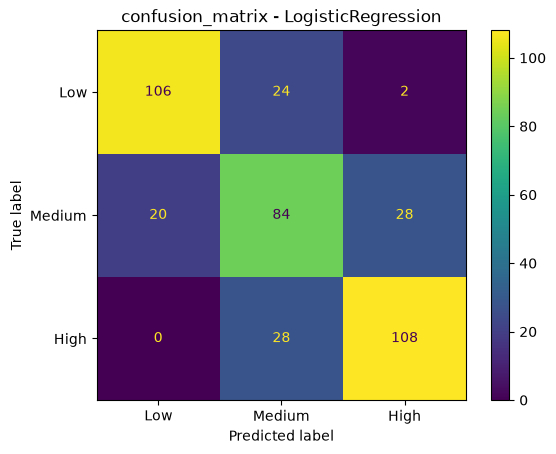

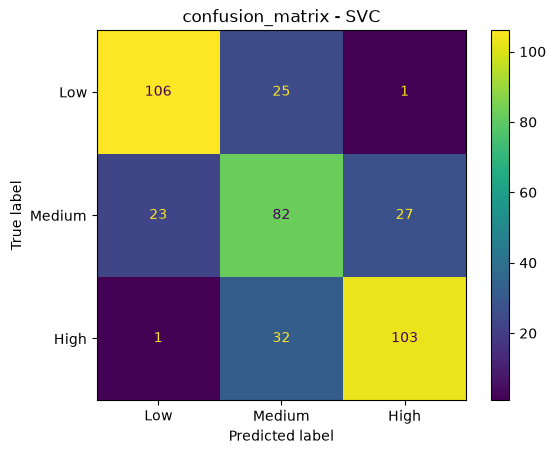

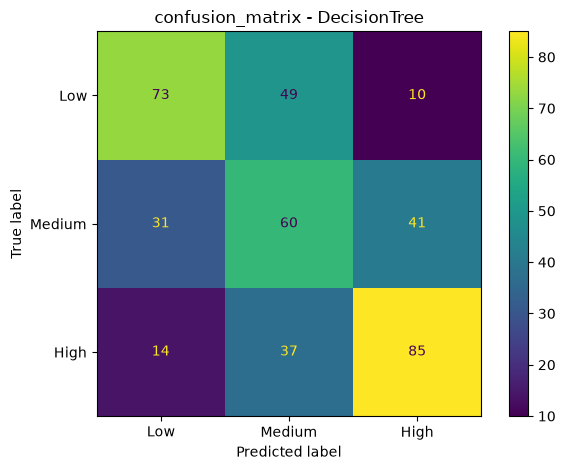

In [16]:
# Matrice de confusion
for model, y_pred in y_preds.items():
    ConfusionMatrixDisplay.from_predictions(
        y_test, 
        y_pred, 
        labels=['Low', 'Medium', 'High'],
    )
    plt.title(f"confusion_matrix - {model}")
    
plt.tight_layout()
plt.show()

Selon les métriques, les modèles les plus prometteurs sont: la regression linéaire et le SVM.

In [28]:
# Optimisation des modèles avec GridSearch
grid_rl = GridSearchCV(
    estimator=rl_pipeline,
    param_grid=[
        {
            'entrainement__penalty': ['l2'],
            'entrainement__solver': ['lbfgs', 'saga'],
            'entrainement__C': [0.001, 0.01, 0.1, 1, 10, 100],
            'entrainement__max_iter': [100, 500, 1000]
        },
        {
            'entrainement__penalty': ['l1'],
            'entrainement__solver': ['liblinear', 'saga'],
            'entrainement__C': [0.001, 0.01, 0.1, 1, 10, 100],
            'entrainement__max_iter': [100, 500, 1000]
        },
        {
            'entrainement__penalty': ['elasticnet'],
            'entrainement__solver': ['saga'],
            'entrainement__C': [0.001, 0.01, 0.1, 1, 10, 100],
            'entrainement__l1_ratio': [0.2, 0.5, 0.8],
            'entrainement__max_iter': [500, 1000]
        },
        {
            'entrainement__penalty': [None],
            'entrainement__solver': ['lbfgs'],
            'entrainement__max_iter': [500, 1000]
        }
    ],
    scoring='f1_weighted',
    cv=5,
    return_train_score=True,
)

grid_rl.fit(X_train, y_train)

c:\Users\youco\Desktop\Pr-diction-du-risque-de-sant-mentale-chez-les-tudiants\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
c:\Users\youco\Desktop\Pr-diction-du-risque-de-sant-mentale-chez-les-tudiants\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...'balanced'))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","[{'entrainement__C': [0.001, 0.01, ...], 'entrainement__max_iter': [100, 500, ...], 'entrainement__penalty': ['l2'], 'entrainement__solver': ['lbfgs', 'saga']}, {'entrainement__C': [0.001, 0.01, ...], 'entrainement__max_iter': [100, 500, ...], 'entrainement__penalty': ['l1'], 'entrainement__solver': ['liblinear', 'saga']}, ...]"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'f1_weighted'
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"return_train_score return_train_score: bool, default=FalseIf ``False``, the ``cv_results_`` attribute will not include trainingscores.Computing training scores is used to get insights on how differentparameter settings impact the overfitting/underfitting trade-off.However computing the scores on the training set can be computationallyexpensive and is not strictly required to select the parameters thatyield the best generalization performance... versionadded:: 0.19.. versionchanged:: 0.21 Default value was changed from ``True`` to ``False``",True
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute

In [31]:
# Optimisation des modèles avec GridSearch
grid_svc = GridSearchCV(
    estimator=svc_pipeline,
    param_grid={
        'entraînement__C': [0.1, 1, 10, 100],
        'entraînement__kernel': ['linear', 'rbf'],
        'entraînement__gamma': ['scale', 'auto', 0.01, 0.1]
    },
    scoring='f1_weighted',
    cv=5,
    return_train_score=True,
)

grid_svc.fit(X_train, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...'balanced'))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'entraînement__C': [0.1, 1, ...], 'entraînement__gamma': ['scale', 'auto', ...], 'entraînement__kernel': ['linear', 'rbf']}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'f1_weighted'
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"return_train_score return_train_score: bool, default=FalseIf ``False``, the ``cv_results_`` attribute will not include trainingscores.Computing training scores is used to get insights on how differentparameter settings impact the overfitting/underfitting trade-off.However computing the scores on the training set can be computationallyexpensive and is not strictly required to select the parameters thatyield the best generalization performance... versionadded:: 0.19.. versionchanged:: 0.21 Default value was changed from ``True`` to ``False``",True
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``

In [32]:
# Performances des modèles
print(f"LogisticRegression :{grid_rl.best_score_}")
print(f"SVC :{grid_svc.best_score_}")

LogisticRegression :0.7643508839792528
SVC :0.7619432988983126


presque le même mais avec un plus pour la regression logistique

In [33]:
rl_y_pred = grid_rl.predict(X_test)

print(f"accuracy : {accuracy_score(y_test, rl_y_pred)}")
print(f"precision : {precision_score(y_test, rl_y_pred, average="weighted")}")
print(f"recall : {recall_score(y_test, rl_y_pred, average="weighted")}")
print(f"f1-score : {f1_score(y_test, rl_y_pred, average="weighted")}")

accuracy : 0.7375
precision : 0.739273139699919
recall : 0.7375
f1-score : 0.7382936988105527


In [34]:
svc_y_pred = grid_svc.predict(X_test)

print(f"accuracy : {accuracy_score(y_test, svc_y_pred)}")
print(f"precision : {precision_score(y_test, svc_y_pred, average="weighted")}")
print(f"recall : {recall_score(y_test, svc_y_pred, average="weighted")}")
print(f"f1-score : {f1_score(y_test, svc_y_pred, average="weighted")}")

accuracy : 0.7425
precision : 0.7427770345596433
recall : 0.7425
f1-score : 0.7426085139577645


à un moment donné, on est tombé dans le sur-apprentissage.

In [35]:
stockage_model = os.path.join("..", "models")

In [ ]:
# Sauvegarde
joblib.dump(grid_rl, os.path.join(stockage_model, "rl_model.joblib"))

['..\\models\\rl_model.joblib']